In [52]:
import sys
import os
import json
import torch
import pandas as pd
import random
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np


# %%
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
    # os.chdir("/Volumes/T7-storage/NOFE/dMRI/scripts/" )
    os.chdir("/Users/siche9897/Github/NOFE/dMRI/scripts/")
else:
    device = torch.device("cpu")
print(f'using Device: {device}')

project_root = Path.cwd().parent.parent
sys.path.insert(0, str(project_root / 'src'))
sys.path.insert(0, str(Path.cwd().parent / 'scripts'))

sys.path.append(f"{project_root}src/")
# Import utilities
from utilities import KernelNN, KernelNN_subgraph, setup_device, get_output_affinities

from dataset_utilities import (
    GraphLMDBWriter,
    #GraphLMDBReader,
)


using Device: mps


In [53]:
# os.system("rsync -r springfield:~/new/NOFE/dMRI/trained_models/* ../trained_models/")

In [54]:
# choose data
model_type = 'regular'


# ---------------------------------------------------------------------------
sys.path.append(f"{project_root}/dMRI/scripts/")
from utilities_dMRI import dMRI_Graph_Generator as Data_Generator


# Paths
trained_models_path = project_root / 'dMRI' / 'trained_models' / model_type
training_logs_path = trained_models_path / 'logs'
data_path = project_root.parent / 'dMRI' / 'data'  # Adjust if needed

print('Available models:\n')
files = sorted(os.listdir(trained_models_path), reverse=True)

for i, f in enumerate(files):
    if Path(f).suffix == ".pth":
        print(f'[{i}] {f}')


Available models:

[1] base_2026-04-29_t11-16-23.pth
[2] base_2026-04-29_t01-33-12.pth


In [55]:
# Set model ID
# model_id = 'base-2026-03-17_t17-43-50.pth'
# model_id = 'base_2026-04-29_t01-33-12.pth'
model_id = 'base_2026-04-29_t11-16-23.pth'



# ---------------------------------------------------------------------------
if model_id.endswith('.pth'):
    model_id = model_id[:-4]

# Load full configuration (includes model, dataset, and training configs)
config_path = f'{training_logs_path}/configs/{model_id}.json'
with open(config_path, 'r') as f:
    config = json.load(f)

# Load loss records
loss_df = pd.read_csv(f'{training_logs_path}/loss_records/{model_id}.csv')

print('Configuration:')
for key, value in config.items():
    print(f'  {key}: {value}')

print(f'\Training completed {len(loss_df)} epochs')
print(f'Final training loss: {loss_df["loss"].iloc[-1]:.4f}')
print(f'Final validation loss: {loss_df["val_loss"].iloc[-1]:.4f}')

Configuration:
  mode: regular
  model_config_path: regular/model_configs/base.json
  dataset_id: base_many
  dataset_path: ../datasets/regular
  epochs: 100
  learning_rate: 0.0005
  scheduler_step: 5
  scheduler_gamma: 0.9
  random_seed: 42
  use_gradient_clipping: False
  track_gradients: False
  checkpoint_every: 5
  width: 32
  ker_width: 32
  depth: 3
  node_features: 143
  edge_attr: 7
  out_width: 3
  data_folder_path: ../data/
  dataset_save_path: ../datasets/regular/
  N: 10000
  k: 10
  perplexity: 10
  sampling_method: random
  train_samples_per_file: 100
  test_samples_per_file: 20
  feature_mode: channel_only
  sigma_method: variance
\Training completed 101 epochs
Final training loss: 223.2576
Final validation loss: 204.7828


In [56]:
# # === NaN 诊断：检查 LMDB 数据集中是否存在 NaN ===
# from utilities import GraphLMDBReader

# train_lmdb_path = str(project_root / 'dMRI' / 'datasets' / 'regular' / 'base_many_train.lmdb')
# train_reader = GraphLMDBReader(train_lmdb_path)
# # 
# batch = train_reader[0]
# print(f'input_affinities NaN? {torch.isnan(batch.input_affinities).any().item()}')
# print(f'input_affinities min/max: {batch.input_affinities.min().item():.6f} / {batch.input_affinities.max().item():.6f}')
# print(f'x (node features) NaN?   {torch.isnan(batch.x).any().item()}')
# print(f'x min/max:                {batch.x.min().item():.6f} / {batch.x.max().item():.6f}')

In [57]:
# # === NaN 诊断第二步：检查原始数据和 b0 mask ===
# import nibabel as nib
# import numpy as np
# from dipy.core.gradients import gradient_table

# data_dir = '../data/132118/T1w/Diffusion_7T/'

# dwi_img = nib.load(data_dir + 'data.nii.gz')
# data = dwi_img.get_fdata().astype(np.float32)
# bvals = np.loadtxt(data_dir + 'bvals')
# bvecs = np.loadtxt(data_dir + 'bvecs')
# gtab = gradient_table(bvals, bvecs=bvecs)

# print(f'数据形状: {data.shape}')
# print(f'b0s_mask 中 True 的数量（b0 volumes）: {gtab.b0s_mask.sum()}')
# print(f'bvals 中的唯一值: {np.unique(bvals)}')
# print(f'原始数据有 NaN? {np.isnan(data).any()}')
# print(f'原始数据有 Inf? {np.isinf(data).any()}')
# print(f'原始数据 min/max: {data.min():.4f} / {data.max():.4f}')

In [58]:
# # === 验证修复：b0_threshold=100 后是否能正常归一化 ===
# from dipy.core.gradients import gradient_table
# import importlib, utilities_dMRI
# importlib.reload(utilities_dMRI)
# from utilities_dMRI import dMRI_Graph_Generator

# gen = dMRI_Graph_Generator(None)
# gen.load_data('../data/132118/T1w/Diffusion_7T/')

# print(f'b0 volumes 数量: {gen.da.shape}')
# print(f'归一化后 NaN? {torch.isnan(gen.da).any().item()}')
# print(f'归一化后 min/max: {gen.da.min().item():.4f} / {gen.da.max().item():.4f}')

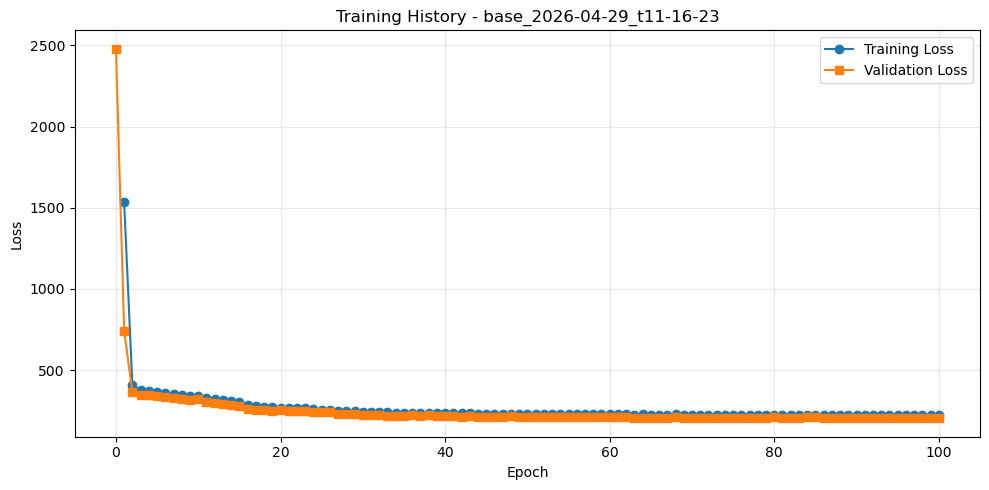

In [59]:
# Plot training history
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(loss_df['epoch'], loss_df['loss'], label='Training Loss', marker='o')
ax.plot(loss_df['epoch'], loss_df['val_loss'], label='Validation Loss', marker='s')
ax.set_xlabel('Epoch')
ax.set_ylabel('Loss')
ax.set_title(f'Training History - {model_id}')
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [60]:
model = KernelNN(
    width=config['width'],
    ker_width=config['ker_width'],
    depth=config['depth'],
    ker_in=config['edge_attr'],
    in_width=config['node_features'],
    out_width=config['out_width']
).to(device)

# Load trained weights
model_path = f'{trained_models_path}/{model_id}.pth'
model.load_state_dict(torch.load(model_path, map_location=device))
model.eval()

print(f'Model loaded: {model_id}')
print(f'Total parameters: {sum(p.numel() for p in model.parameters()):,}')

Model loaded: base_2026-04-29_t11-16-23
Total parameters: 40,867


In [61]:
globals().update(config)

In [62]:
Generator = Data_Generator(data_path)
# Generator.load_data('../data/100206/T1w/Diffusion/')
# Generator.load_data('../data/132118/T1w/Diffusion_7T/')
Generator.load_data('../data/115017/T1w/Diffusion_7T/')


print('generate data')
graph = Generator.sample_graph(N=N, k=k, perplexity=perplexity, sampling_method=sampling_method, gen_feature_mode=feature_mode)
sample = graph.to(device)


print('predict results')
output = model(sample).detach().cpu().numpy()

generate data


/Users/siche9897/Github/NOFE/src/generator_utility.py:532: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  normed_coords = torch.tensor(normed_coords, device=device, dtype=torch.float32)


predict results


In [70]:

N = 20000

print('generate data')
graph = Generator.sample_graph(N=N, k=k, perplexity=perplexity, sampling_method=sampling_method, gen_feature_mode=feature_mode)
sample = graph.to(device)


print('predict results')
output = model(sample).detach().cpu().numpy()

generate data


/Users/siche9897/Github/NOFE/src/generator_utility.py:532: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  normed_coords = torch.tensor(normed_coords, device=device, dtype=torch.float32)


predict results


In [ ]:
# graph.normed_coords.detach().cpu().numpy().shape

(20000, 3)

In [72]:
coords = graph.normed_coords.detach().cpu().numpy()
p1 = np.percentile(output, 1, axis=0)
p99 = np.percentile(output, 99, axis=0)

eps = 1e-8
RGB_brain = (output - p1) / (p99 - p1 + eps)

RGB_brain = np.clip(RGB_brain, 0, 1)

In [65]:
import napari
viewer = napari.Viewer(ndisplay=3)
viewer.add_points(coords, face_color=RGB_brain, size=0.02)

<Points layer 'coords' at 0x3051a6dd0>

In [75]:
from scipy.interpolate import griddata

# grid_res = 50  # or higher for more detail
grid_res = 1000  # or higher for more detail --- IGNORE ---
x = np.linspace(0, 1, grid_res)
y = np.linspace(0, 1, grid_res)
z = np.linspace(0, 1, grid_res)
X, Y, Z = np.meshgrid(x, y, z, indexing='ij')
grid_points = np.vstack([X.ravel(), Y.ravel(), Z.ravel()]).T

# Interpolate each channel
R = griddata(coords, RGB_brain[:, 0], grid_points, method='linear', fill_value=0).reshape(grid_res, grid_res, grid_res)
G = griddata(coords, RGB_brain[:, 1], grid_points, method='linear', fill_value=0).reshape(grid_res, grid_res, grid_res)
B = griddata(coords, RGB_brain[:, 2], grid_points, method='linear', fill_value=0).reshape(grid_res, grid_res, grid_res)

RGB_grid = np.stack([R, G, B], axis=-1)

viewer = napari.Viewer(ndisplay=3)
viewer.add_image(RGB_grid, rgb=True)

: 